In [39]:
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.optimize import root
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import math
import numpy as np
# Fundamental constants in SI
G = 6.67430e-11            # gravitational constant [m^3 kg^-1 s^-2]
c = 2.99792458e8           # speed of light [m s^-1]
hbar = 1.054571817e-34     # reduced Planck constant [J s]
M_sun = 1.98847e30         # solar mass [kg]


# Basic unit conversions
eV_to_J = 1.602176634e-19
MeV_to_J = 1.0e6 * eV_to_J

J_to_eV = 1.0 / eV_to_J
J_to_MeV = 1.0 / MeV_to_J

fm_to_m = 1.0e-15
m_to_fm = 1.0 / fm_to_m

km_to_m = 1.0e3
m_to_km = 1.0 / km_to_m

def kg_to_MeV_c2(m_kg):
    return m_kg * c**2 * J_to_MeV


def MeV_c2_to_kg(m_MeV):
    return m_MeV * MeV_to_J / c**2

MeV_fm3_to_J_m3 = MeV_to_J / fm_to_m**3
J_m3_to_MeV_fm3 = 1.0 / MeV_fm3_to_J_m3

def MeV_fm3_to_SI(x):
    return x * MeV_fm3_to_J_m3
def SI_to_MeV_fm3(x):
    return x * J_m3_to_MeV_fm3




In [40]:
# Boundary values from the 2014 paper
#mu in MeV, n0 in fm, P in Mev/fm^3,
# GB-II boundary values
n0 = 0.16
n_begin = 1.1*n0

mu_begin = 977.5       # MeV
P_begin = 3.542        # MeV/fm^3

mu_end = 2600.0        # MeV
X_pqcd = 1.2

# Internal Bag 1 -> Bag 2 join
# Changed value from 1350 to 1500
mu_split_II = 1500.0

### EOS for : Piecewise Bag Model.
Used form of Bag Model EOS similar to the one in Alford et.al 2005. In the paper an extension of the quark chemical potential is used. The relation with the pressure Pqm = - Ohmqm is used to construct the EOS for pressure. 

$$
P_i(\mu_B)
=
A_i\left(\frac{\mu_B}{1000}\right)^4
-
C_i\left(\frac{\mu_B}{1000}\right)^2
-
B_i
$$



In [41]:
# EOS for : Pressure as a function of baryon dfensity
# Changed to EOS for a bag model
def fit_piecewise_bag(mu0, P0, n0b, muc, X, mue=2600.0):

    u0, uc, ue = mu0/1000, muc/1000, mue/1000

    Pq = pqcd_pressure_mu(mue, X=X)
    nq = pqcd_number_density_mu(mue, X=X)

    M = np.array([
        [u0**4, -u0**2, -1, 0, 0, 0],
        [4*u0**3/1000, -2*u0/1000, 0, 0, 0, 0],

        [uc**4, -uc**2, -1, -uc**4, uc**2, 1],
        [4*uc**3/1000, -2*uc/1000, 0,
         -4*uc**3/1000, 2*uc/1000, 0],

        [0, 0, 0, ue**4, -ue**2, -1],
        [0, 0, 0, 4*ue**3/1000, -2*ue/1000, 0]
    ])

    b = np.array([P0, n0b, 0, 0, Pq, nq])

    return np.linalg.solve(M, b)


def bag_thermo(mu, coeffs, segment):

    u = np.asarray(mu)/1000
    A1,C1,B1,A2,C2,B2 = coeffs

    A,C,B = (A1,C1,B1) if segment == 1 else (A2,C2,B2)

    P = A*u**4 - C*u**2 - B
    n = (4*A*u**3 - 2*C*u)/1000
    E = 3*A*u**4 - C*u**2 + B

    dn_dmu = (12*A*u**2 - 2*C)/1e6
    cs2 = n/(np.asarray(mu)*dn_dmu)

    return P,n,E,cs2

In [42]:
# Low density Region EOS:
#Chiral EFT EOS model
from scipy.optimize import brentq, root

T0 = 36.84
alpha = 5.87
eta = 3.81
gamma_chi = 4/3
hbarc = 197.3269804
mN = 939.0                  # MeV

# electron chemical potential
def mu_electron(n, x):
    return hbarc*(3*np.pi**2*x*n)**(1/3)

def deps_dx(n, x, alphaL, etaL):
    nb = n/n0
    A = 2*alpha - 4*alphaL
    B = 2*eta - 4*etaL

    return T0*((x**(2/3)-(1-x)**(2/3))*(2*nb)**(2/3)
               - A*(1-2*x)*nb
               + B*(1-2*x)*nb**gamma_chi)

def beta_x(n, alphaL, etaL):
    f = lambda x: deps_dx(n,x,alphaL,etaL) + mu_electron(n,x)
    return brentq(f, 1e-8, 0.499999)


In [43]:
# Nuclear equations for ep and P
def chiral_eps(n, x, alphaL, etaL):
    nb = n/n0

    kinetic = (3/5)*(x**(5/3)+(1-x)**(5/3))*(2*nb)**(2/3)

    A = ((2*alpha-4*alphaL)*x*(1-x) + alphaL)
    B = ((2*eta-4*etaL)*x*(1-x) + etaL)

    return T0*(kinetic - A*nb + B*nb**gamma_chi)
#Baryonic Pressure and electron pressure
def chiral_pressure(n, alphaL, etaL):
    x = beta_x(n, alphaL, etaL)
    nb = n/n0

    A = ((2*alpha-4*alphaL)*x*(1-x) + alphaL)
    B = ((2*eta-4*etaL)*x*(1-x) + etaL)

    Pb = n0*T0*((1/5)*(x**(5/3)+(1-x)**(5/3))*(2*nb)**(5/3)
                - A*nb**2 + gamma_chi*B*nb**(gamma_chi+1))

    mu_e = mu_electron(n,x)
    Pe = 0.25*mu_e*x*n

    return Pb + Pe

def chiral_energy(n, alphaL, etaL):
    x = beta_x(n, alphaL, etaL)
    eps = chiral_eps(n,x,alphaL,etaL)

    mu_e = mu_electron(n,x)
    Ee = 0.75*mu_e*x*n

    return n*(mN + eps) + Ee
    

In [44]:
#Restricting the region of our values for al between 1.18 - 1.59 and nl between 0.64 - 1.11
P_target = 3.542
mu_target = 977.5

def match_chiral(z):
    alphaL, etaL = z

    P = chiral_pressure(n_begin, alphaL, etaL)
    E = chiral_energy(n_begin, alphaL, etaL)
    mu = (E + P)/n_begin

    return [P-P_target, mu-mu_target]

alphaL, etaL = root(match_chiral, [1.5,1.05]).x

print("alphaL =", alphaL)
print("etaL =", etaL)
P_chi_end = chiral_pressure(n_begin, alphaL, etaL)
E_chi_end = chiral_energy(n_begin, alphaL, etaL)
mu_chi_end = (E_chi_end + P_chi_end)/n_begin

print("P =", P_chi_end)
print("E =", E_chi_end)
print("mu_B =", mu_chi_end)

alphaL = 1.4641889049557169
etaL = 1.0214198935378929
P = 3.54200000000025
E = 168.49800000000087
mu_B = 977.5000000000064


In [45]:
# PQCD High density Region
# pQCD parameters for EOS II

X_pqcd = 1.2

c1 = 0.9008
d1 = 0.5034
d2 = 1.452
nu1 = 0.3553
nu2 = 0.9101

hbarc_GeVfm = 0.1973269804
mu_pqcd_begin = 2600.0 

def pqcd_ab(X):
    a = d1*X**(-nu1)
    b = d2*X**(-nu2)
    return a, b
#PSB term of noninteracting massless quark flavours
def pqcd_pressure_mu(muB, X=X_pqcd):
    u = muB/1000.0                     # MeV -> GeV
    a, b = pqcd_ab(X)

    P_SB = (3/(4*np.pi**2))*(u/3)**4
    P_nat = P_SB*(c1 - a/(u-b))

    return P_nat*1000/hbarc_GeVfm**3

# Baryon Number Density
def pqcd_number_density_mu(muB, X=X_pqcd):
    u = muB/1000.0
    a, b = pqcd_ab(X)

    C = 1/(108*np.pi**2)
    f = c1 - a/(u-b)
    fp = a/(u-b)**2

    return C*(4*u**3*f + u**4*fp)/hbarc_GeVfm**3

def pqcd_energy_mu(muB, X=X_pqcd):
    P = pqcd_pressure_mu(muB, X)
    n = pqcd_number_density_mu(muB, X)
    return muB*n - P



In [46]:
#SOS CHECK 
def pqcd_cs2_mu(muB, X=X_pqcd):
    u = muB/1000.0
    a, b = pqcd_ab(X)

    C = 1/(108*np.pi**2)
    f = c1 - a/(u-b)
    fp = a/(u-b)**2
    fpp = -2*a/(u-b)**3

    n = pqcd_number_density_mu(muB, X)

    dn_du = C*(12*u**2*f + 8*u**3*fp + u**4*fpp)/hbarc_GeVfm**3

    return n/(u*dn_du)
    

### Construction of EOS II for the bag model
New construction  = stiff Chiral EOS -> Bag 1 - > Bag 2 - > pQCD

In [47]:
# Construct GB-II

bag_coeff_II = fit_piecewise_bag(
    mu_begin, P_begin, n_begin,
    mu_split_II, X_pqcd, mu_end
)

mu_bag1_II = np.linspace(mu_begin, mu_split_II, 300)
mu_bag2_II = np.linspace(mu_split_II, mu_end, 500)

P_bag1_II, n_bag1_II, E_bag1_II, cs1_II = bag_thermo(
    mu_bag1_II, bag_coeff_II, 1
)

P_bag2_II, n_bag2_II, E_bag2_II, cs2_II = bag_thermo(
    mu_bag2_II, bag_coeff_II, 2
)

P_bag_split_II = P_bag1_II[-1]
n_bag_split_II = n_bag1_II[-1]

print("GB-II coefficients =", bag_coeff_II)
print("Bag 1 cs2 =", cs1_II.min(), "to", cs1_II.max())
print("Bag 2 cs2 =", cs2_II.min(), "to", cs2_II.max())

GB-II coefficients = [  13.57156451  -64.09014603   70.08726755  117.85884235  405.20260425
 -457.86707651]
Bag 1 cs2 = 0.5061019597138008 to 0.6344456497806661
Bag 2 cs2 = 0.10554267239882603 to 0.27159032030250757


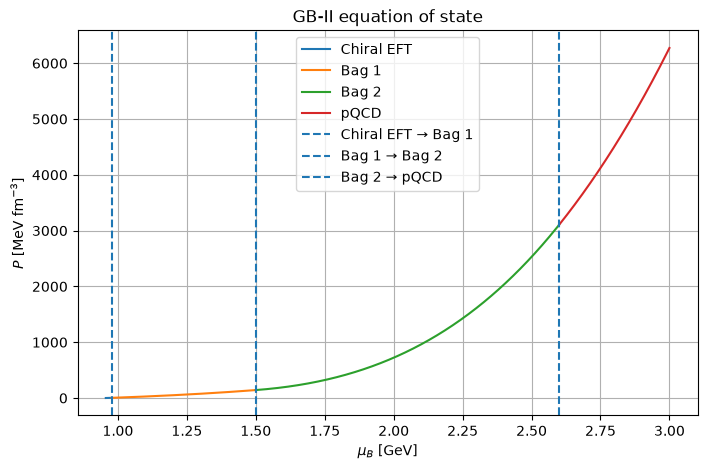

In [48]:

# Chiral EFT
n_chi = np.linspace(0.55*n0, n_begin, 250)

P_chi = np.array([
    chiral_pressure(n, alphaL, etaL) for n in n_chi
])

E_chi = np.array([
    chiral_energy(n, alphaL, etaL) for n in n_chi
])

mu_chi = (E_chi + P_chi)/n_chi

# pQCD
mu_qcd = np.linspace(mu_end, 3000, 300)
P_qcd = pqcd_pressure_mu(mu_qcd, X=X_pqcd)

plt.figure(figsize=(8,5))

plt.plot(mu_chi/1000, P_chi, label="Chiral EFT")
plt.plot(mu_bag1_II/1000, P_bag1_II, label="Bag 1")
plt.plot(mu_bag2_II/1000, P_bag2_II, label="Bag 2")
plt.plot(mu_qcd/1000, P_qcd, label="pQCD")

plt.axvline(mu_begin/1000, linestyle="--",
            label="Chiral EFT → Bag 1")

plt.axvline(mu_split_II/1000, linestyle="--",
            label="Bag 1 → Bag 2")

plt.axvline(mu_end/1000, linestyle="--",
            label="Bag 2 → pQCD")

plt.xlabel(r"$\mu_B$ [GeV]")
plt.ylabel(r"$P$ [MeV fm$^{-3}$]")
plt.title("GB-II equation of state")
plt.grid()
plt.legend()
plt.show()

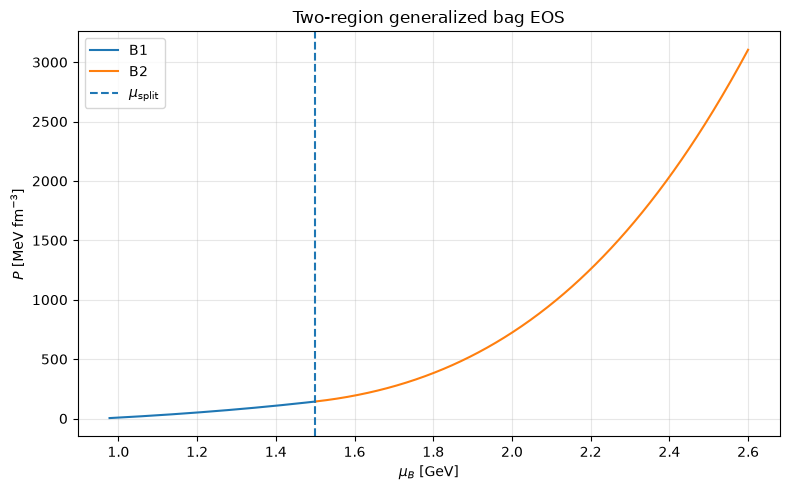

In [49]:
# Plot only the two generalized-bag regions

plt.figure(figsize=(8,5))

plt.plot(
    mu_bag1_II/1000,
    P_bag1_II,
    label="B1"
)

plt.plot(
    mu_bag2_II/1000,
    P_bag2_II,
    label="B2"
)

plt.axvline(
    mu_split_II/1000,
    linestyle="--",
    label=r"$\mu_{\rm split}$"
)

plt.xlabel(r"$\mu_B$ [GeV]")
plt.ylabel(r"$P$ [MeV fm$^{-3}$]")
plt.title("Two-region generalized bag EOS")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
# Chiral EFT E(P)
n_chi_grid = np.linspace(0.55*n0, n_begin, 400)

P_chi_grid = np.array([
    chiral_pressure(n,alphaL,etaL) for n in n_chi_grid
])

E_chi_grid = np.array([
    chiral_energy(n,alphaL,etaL) for n in n_chi_grid
])

chi_E_of_P = PchipInterpolator(
    P_chi_grid,E_chi_grid,extrapolate=False
)

P_chi_min = P_chi_grid[0]


# Bag E(P)
bag1_E_of_P_II = PchipInterpolator(
    P_bag1_II,E_bag1_II,extrapolate=False
)

bag2_E_of_P_II = PchipInterpolator(
    P_bag2_II,E_bag2_II,extrapolate=False
)


# pQCD E(P)
mu_qcd_grid = np.linspace(mu_end,6000,800)

P_qcd_grid = pqcd_pressure_mu(
    mu_qcd_grid,X=X_pqcd
)

E_qcd_grid = pqcd_energy_mu(
    mu_qcd_grid,X=X_pqcd
)

qcd_E_of_P = PchipInterpolator(
    P_qcd_grid,E_qcd_grid,extrapolate=False
)

P_qcd_start = P_qcd_grid[0]

print("Chiral → Bag 1:", P_begin)
print("Bag 1 → Bag 2:", P_bag_split_II)
print("Bag 2 → pQCD:", P_qcd_start)




def interpolate_table(value,table):
    value=float(value)
    lower,upper=float(table.x[0]),float(table.x[-1])
    tolerance=1e-10*max(1.,abs(lower),abs(upper))
    if not np.isfinite(value) or value<lower-tolerance or value>upper+tolerance:
        raise ValueError('Requested value is outside this EOS table.')
    result=float(table(np.clip(value,lower,upper)))
    if not np.isfinite(result):
        raise ValueError('The EOS interpolation returned a non-finite value.')
    return result


Chiral → Bag 1: 3.542
Bag 1 → Bag 2: 142.82160633529497
Bag 2 → pQCD: 3104.5637057821496


In [51]:
# Piecewise full density equation
def full_e_density(P):

    P_MeV = float(SI_to_MeV_fm3(P))

    if P_MeV < P_chi_min*(1-1e-12):
        raise ValueError("Pressure below EOS range.")

    P_MeV = max(P_MeV, P_chi_min)

    if P_MeV <= P_begin:
        E_MeV = interpolate_table(P_MeV,chi_E_of_P)

    elif P_MeV <= P_bag_split_II:
        E_MeV = interpolate_table(P_MeV,bag1_E_of_P_II)

    elif P_MeV < P_qcd_start:
        E_MeV = interpolate_table(P_MeV,bag2_E_of_P_II)

    else:
        E_MeV = interpolate_table(P_MeV,qcd_E_of_P)

    return MeV_fm3_to_SI(E_MeV)


In [52]:
P_surface = MeV_fm3_to_SI(P_chi_min)
def tov_equations(r,y):
    m,P = y
    if r <= 0.0:
        print("TOV equations cannot be evaluated at singularity.")

    if P <= P_surface:
        return [0.0, 0.0]
    E = full_e_density(P)
    
    dmdr = 4.0 * np.pi * r**2 * E/ c**2
    t1 = G * E * m / (c**2 * r**2)

    t2 = 1.0 + P / E

    t3 = 1.0 + (4.0 * np.pi * r**3 * P) / (m * c**2)

    t4 = 1.0 - (2.0 * G * m) / (c**2 * r)

    dPdr = -t1 * t2 * t3 / t4
    return [dmdr, dPdr]



In [53]:
P_surface = MeV_fm3_to_SI(P_chi_min)

def surface_event(r, y):
    return y[1] - P_surface

surface_event.terminal = True
surface_event.direction = -1

from scipy.integrate import solve_ivp
 # in mev
def solve_star(P_c_MeV, return_profile=False):
    P_c = MeV_fm3_to_SI(P_c_MeV)
    E_c = full_e_density(P_c)

    r_start = 1e-3
    m_start = (4*np.pi/3)*r_start**3*E_c/c**2

    sol = solve_ivp(
        tov_equations,
        [r_start, 5e4],
        [m_start, P_c],
        events=surface_event,
        rtol=1e-6,
        max_step=20
    )

    if len(sol.t_events[0]) == 0:
        if return_profile:
            return np.nan, np.nan, None
        return np.nan, np.nan

    R = sol.t_events[0][0]
    M = sol.y_events[0][0][0]

    if return_profile:
        return M/M_sun, R/1000, sol

    return M/M_sun, R/1000

M_test, R_test = solve_star(500.0)

print("Mass =", M_test, "M_sun")
print("Radius =", R_test, "km")

Mass = 2.678759534647516 M_sun
Radius = 13.995767155586753 km


## GB-III alongside GB-II: shared analytical stiff nuclear EOS
The models use the same nuclear endpoint at n=1.1*n0, P=3.542 MeV/fm^3 and
mu_B=977.5 MeV. Their original generalized-bag settings are retained:

| Parameter | GB-II | GB-III |
| --- | ---: | ---: |
| Bag 1 / bag 2 joining chemical potential [MeV] | 1500 | 1125 |
| pQCD scale X | 1.2 | 1.9 |
| Upper matching chemical potential [MeV] | 2600 | 2600 |


In [54]:
# EOS III parameters: the analytical chiral functions above are reused.
# GB-III
mu_split_III = 1125.0
mu_end_III = 2600.0
X_III = 1.9

bag_coeff_III = fit_piecewise_bag(
    mu_begin,P_begin,n_begin,
    mu_split_III,X_III,mu_end_III
)

print("GB-III coefficients =",bag_coeff_III)

GB-III coefficients = [ 33.26842933 -26.44919115  52.10418372 103.83559842 152.17395563
 -60.93077634]


### GB-III pressure, chemical potential and energy density
Use bag_thermo with the two fitted coefficient sets. Pressure and baryon density
are continuous at the middle join. Total energy density follows from
epsilon=mu_B*n_B-P. The PCHIP tables provide the TOV energy as a function of pressure.


In [55]:
mu_bag1_III = np.linspace(mu_begin,mu_split_III,300)
mu_bag2_III = np.linspace(mu_split_III,mu_end_III,500)

P_bag1_III,n_bag1_III,E_bag1_III,cs1_III = bag_thermo(
    mu_bag1_III,bag_coeff_III,1
)

P_bag2_III,n_bag2_III,E_bag2_III,cs2_III = bag_thermo(
    mu_bag2_III,bag_coeff_III,2
)

P_bag_split_III = P_bag1_III[-1]

bag1_E_of_P_III = PchipInterpolator(
    P_bag1_III,E_bag1_III,extrapolate=False
)

bag2_E_of_P_III = PchipInterpolator(
    P_bag2_III,E_bag2_III,extrapolate=False
)

### Add pQCD and reuse the same nuclear interpolation
Pass X=1.9 explicitly to the existing pQCD functions. The shared chi_E_of_P
table is retained. The fitted generalized bags join pQCD at 2600 MeV in pressure,
baryon density and total energy density, up to floating-point roundoff.


In [56]:
mu_qcd_grid_III = np.linspace(mu_end_III, 6000.0, 800)
P_qcd_grid_III = pqcd_pressure_mu(mu_qcd_grid_III, X=X_III)
E_qcd_grid_III = pqcd_energy_mu(mu_qcd_grid_III, X=X_III)

qcd_E_of_P_III = PchipInterpolator(
    P_qcd_grid_III, E_qcd_grid_III, extrapolate=False
)
P_qcd_start_III = float(P_qcd_grid_III[0])


def full_e_density_III(P):

    pressure = float(SI_to_MeV_fm3(P))
    if not np.isfinite(pressure) or pressure<P_chi_min*(1-1e-12):
        raise ValueError('Pressure is below the EOS table.')
    pressure = max(pressure,P_chi_min)

    if pressure <= P_begin:
        E = interpolate_table(pressure,chi_E_of_P)

    elif pressure <= P_bag_split_III:
        E = interpolate_table(pressure,bag1_E_of_P_III)

    elif pressure < P_qcd_start_III:
        E = interpolate_table(pressure,bag2_E_of_P_III)

    else:
        E = interpolate_table(pressure,qcd_E_of_P_III)

    return MeV_fm3_to_SI(E)


### Integrate EOS III with the same TOV equations and outer cutoff
The state is [enclosed mass, pressure] in SI units. We start at a tiny positive
radius using the same central mass expansion as the original solver.
The integration stops at the SAME pressure `P_surface` used by EOS II.
Because this pressure corresponds to n=0.55n0 rather than P=0, the reported
radii omit lower-density outer layers. These are comparisons of the existing
notebook models, not exact reproductions of published complete-star radii.

In [57]:
def tov_equations_III(r, y):
    mass, pressure = y
    if pressure <= P_surface:
        return [0.0, 0.0]

    energy = full_e_density_III(pressure)
    dmdr = 4*np.pi*r**2*energy/c**2
    dPdr = (
        -G*(energy + pressure)*(mass + 4*np.pi*r**3*pressure/c**2)
        / (c**2*r**2*(1 - 2*G*mass/(r*c**2)))
    )
    return [dmdr, dPdr]


def surface_event_III(r, y):
    return y[1] - P_surface


surface_event_III.terminal = True
surface_event_III.direction = -1


def solve_star_III(P_c_MeV, return_profile=False):
    central_pressure = MeV_fm3_to_SI(P_c_MeV)
    central_energy = full_e_density_III(central_pressure)
    r_start_III = 1e-3
    mass_start = 4*np.pi*r_start_III**3*central_energy/(3*c**2)

    solution = solve_ivp(
        tov_equations_III, [r_start_III, 5e4],
        [mass_start, central_pressure], events=surface_event_III,
        rtol=1e-6, max_step=20
    )
    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError('EOS III integration did not reach the outer cutoff.')

    radius = solution.t_events[0][0]/1000
    mass = solution.y_events[0][0][0]/M_sun
    if return_profile:
        return mass, radius, solution
    return mass, radius

## EOS I: analytical soft nuclear input
EOS I uses the same nuclear energy expression and beta-equilibrium solve as
EOS II/III, but different fitted alpha_L and eta_L. We fit the soft anchor
at n=1.1n0: P=2.163 MeV/fm^3 and mu_B=965.7 MeV. No existing hard-EOS
parameter is overwritten. Every new name carries the suffix `_I`.

GB-I uses the two fitted generalized bags, mu_join=1650 MeV, X=1.2,
and mu_end=2600 MeV (Kurkela et al. 2014, Table 1, arXiv:1402.6618).
The analytical soft nuclear fit is approximate between the matching points;
its comparison with the seven soft rows of Hebeler et al. 2013 Table 5 is
shown below. It is not the entire 2013 soft EOS continued to high density.


In [58]:
# Fit just the two soft nuclear coefficients, using the existing functions.
n_begin_I = 1.1*n0
P_begin_I = 2.163
mu_begin_I = 965.7


def match_chiral_I(parameters):
    alpha_soft, eta_soft = parameters
    pressure = chiral_pressure(n_begin_I, alpha_soft, eta_soft)
    energy = chiral_energy(n_begin_I, alpha_soft, eta_soft)
    chemical_potential = (energy + pressure)/n_begin_I
    return [pressure - P_begin_I, chemical_potential - mu_begin_I]


fit_I = root(match_chiral_I, [1.2, 0.65])
if not fit_I.success:
    raise RuntimeError(fit_I.message)
np.testing.assert_allclose(fit_I.fun, 0, atol=1e-8)
alphaL_I, etaL_I = fit_I.x


def chiral_pressure_I(n):
    return chiral_pressure(n, alphaL_I, etaL_I)


def chiral_energy_I(n):
    return chiral_energy(n, alphaL_I, etaL_I)


def chiral_mu_I(n):
    return (chiral_energy_I(n) + chiral_pressure_I(n))/n


print('Soft nuclear fit: alphaL_I =', alphaL_I, ', etaL_I =', etaL_I)
print('At 1.1n0: P =', chiral_pressure_I(n_begin_I),
      'E =', chiral_energy_I(n_begin_I),
      'mu_B =', chiral_mu_I(n_begin_I))

Soft nuclear fit: alphaL_I = 1.2153849129191907 , etaL_I = 0.6640439286697408
At 1.1n0: P = 2.1629999999995633 E = 167.80020000000013 mu_B = 965.6999999999981


### Check the fitted soft model against the low-density numerical reference
These are the seven soft entries of Hebeler et al. (2013), Table 5, restricted
to n<=1.1n0. The pressure/energy units are MeV/fm^3. Percent differences use
100*(analytical-reference)/reference. Only the anchor is imposed exactly;
the other rows test the shape of the analytical parameterization.

In [59]:
import pandas as pd

soft_reference_I = np.array([
    [0.5792, 0.4470, 87.90],
    [0.7124, 0.7162, 108.20],
    [0.7861, 0.9094, 119.50],
    [0.8646, 1.1540, 131.50],
    [0.9483, 1.4640, 144.40],
    [1.0371, 1.8510, 158.00],
    [1.1000, 2.1630, 167.80]
])
soft_n_I = soft_reference_I[:, 0]*n0
soft_P_analytic_I = np.array([chiral_pressure_I(n) for n in soft_n_I])
soft_E_analytic_I = np.array([chiral_energy_I(n) for n in soft_n_I])
soft_check_I = pd.DataFrame({
    'n/n0': soft_reference_I[:, 0],
    'P reference': soft_reference_I[:, 1],
    'P analytical': soft_P_analytic_I,
    'P difference [%]': 100*(soft_P_analytic_I/soft_reference_I[:, 1] - 1),
    'E reference': soft_reference_I[:, 2],
    'E analytical': soft_E_analytic_I,
    'E difference [%]': 100*(soft_E_analytic_I/soft_reference_I[:, 2] - 1)
})
display(soft_check_I.round(6))

,n/n0,P reference,P analytical,P difference [%],E reference,E analytical,E difference [%]
0,0.5792,0.4470,0.464622,3.942260,87.9,87.884606,-0.017513
1,0.7124,0.7162,0.734691,2.581868,108.2,108.229612,0.027368
2,0.7861,0.9094,0.927305,1.968892,119.5,119.511660,0.009757
3,0.8646,1.1540,1.170448,1.425340,131.5,131.550120,0.038114
4,0.9483,1.4640,1.476255,0.837104,144.4,144.412448,0.008621
5,1.0371,1.8510,1.856768,0.311631,158.0,158.090471,0.057260
6,1.1000,2.1630,2.163000,-0.000000,167.8,167.800200,0.000119


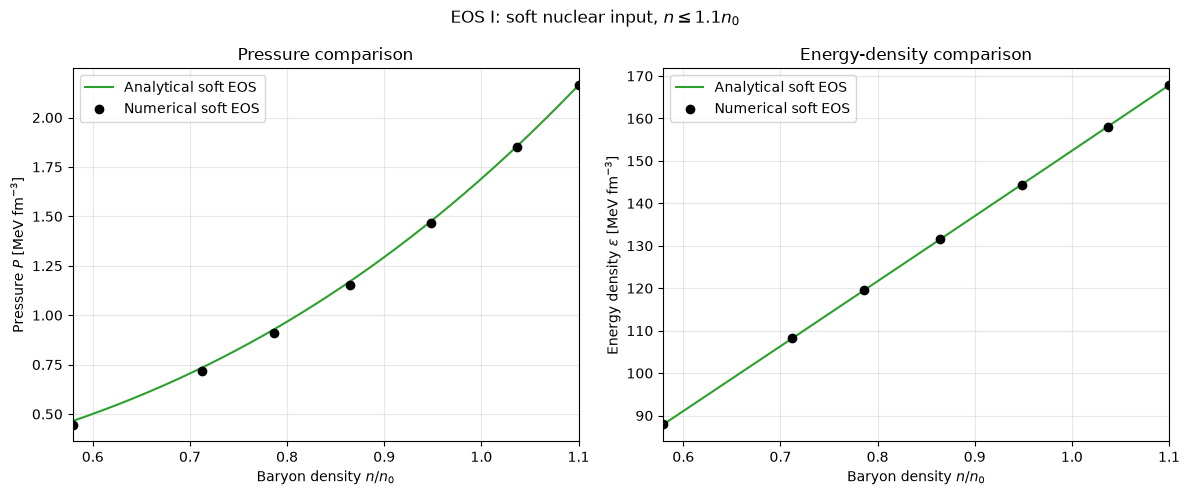

In [60]:
import numpy as np
import matplotlib.pyplot as plt

# Numerical soft EOS from Table 5:
# Columns: n/n0, pressure [MeV/fm^3], energy density [MeV/fm^3].
reference_soft = np.array([
    [0.5792, 0.4470,  87.90],
    [0.7124, 0.7162, 108.20],
    [0.7861, 0.9094, 119.50],
    [0.8646, 1.1540, 131.50],
    [0.9483, 1.4640, 144.40],
    [1.0371, 1.8510, 158.00],
    [1.1000, 2.1630, 167.80]
])

# Evaluate the analytical EOS on a smooth density grid.
n_ratio = np.linspace(reference_soft[0, 0], 1.1, 300)
n_values = n_ratio * n0

P_analytical = np.array([chiral_pressure_I(n) for n in n_values])
E_analytical = np.array([chiral_energy_I(n) for n in n_values])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pressure comparison.
axes[0].plot(
    n_ratio, P_analytical, color="C2",
    label="Analytical soft EOS"
)
axes[0].scatter(
    reference_soft[:, 0], reference_soft[:, 1],
    color="black", marker="o", zorder=3,
    label="Numerical soft EOS"
)
axes[0].set_ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
axes[0].set_title("Pressure comparison")

# Total energy-density comparison.
axes[1].plot(
    n_ratio, E_analytical, color="C2",
    label="Analytical soft EOS"
)
axes[1].scatter(
    reference_soft[:, 0], reference_soft[:, 2],
    color="black", marker="o", zorder=3,
    label="Numerical soft EOS"
)
axes[1].set_ylabel(r"Energy density $\varepsilon$ [MeV fm$^{-3}$]")
axes[1].set_title("Energy-density comparison")

# Formatting shared by both plots.
for ax in axes:
    ax.set_xlabel(r"Baryon density $n/n_0$")
    ax.set_xlim(reference_soft[0, 0], 1.1)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(r"EOS I: soft nuclear input, $n \leq 1.1n_0$")
plt.tight_layout()
plt.show()

In [61]:
# GB-I
mu_split_I = 1650.0
mu_end_I = 2600.0
X_I = 1.2

bag_coeff_I = fit_piecewise_bag(
    mu_begin_I,P_begin_I,n_begin_I,
    mu_split_I,X_I,mu_end_I
)

print("GB-I coefficients =",bag_coeff_I)

GB-I coefficients = [  34.1834613   -27.36822366   53.08928098  120.71229397  443.78127025
 -588.2629676 ]


In [62]:
# Using interpolation to construct the energy density values
# Soft chiral EFT
n_chi_grid_I = np.linspace(0.55*n0,n_begin_I,400)

P_chi_grid_I = np.array([
    chiral_pressure_I(n) for n in n_chi_grid_I
])

E_chi_grid_I = np.array([
    chiral_energy_I(n) for n in n_chi_grid_I
])

# Baryon chemical potential for the normalized-pressure comparison.
mu_chi_grid_I = (E_chi_grid_I + P_chi_grid_I)/n_chi_grid_I

chi_E_of_P_I = PchipInterpolator(
    P_chi_grid_I,E_chi_grid_I,
    extrapolate=False
)

P_chi_min_I = P_chi_grid_I[0]
P_surface_I = MeV_fm3_to_SI(P_chi_min_I)


# Generalized bag
mu_bag1_I = np.linspace(mu_begin_I,mu_split_I,300)
mu_bag2_I = np.linspace(mu_split_I,mu_end_I,500)

P_bag1_I,n_bag1_I,E_bag1_I,cs1_I = bag_thermo(
    mu_bag1_I,bag_coeff_I,1
)

P_bag2_I,n_bag2_I,E_bag2_I,cs2_I = bag_thermo(
    mu_bag2_I,bag_coeff_I,2
)

P_bag_split_I = P_bag1_I[-1]

bag1_E_of_P_I = PchipInterpolator(
    P_bag1_I,E_bag1_I,extrapolate=False
)

bag2_E_of_P_I = PchipInterpolator(
    P_bag2_I,E_bag2_I,extrapolate=False
)


# pQCD
mu_qcd_grid_I = np.linspace(mu_end_I,6000,800)

P_qcd_grid_I = pqcd_pressure_mu(
    mu_qcd_grid_I,X=X_I
)

E_qcd_grid_I = pqcd_energy_mu(
    mu_qcd_grid_I,X=X_I
)

qcd_E_of_P_I = PchipInterpolator(
    P_qcd_grid_I,E_qcd_grid_I,
    extrapolate=False
)

P_qcd_start_I = P_qcd_grid_I[0]


def full_e_density_I(P):

    pressure = float(SI_to_MeV_fm3(P))
    if not np.isfinite(pressure) or pressure<P_chi_min_I*(1-1e-12):
        raise ValueError('Pressure is below the EOS table.')
    pressure = max(pressure,P_chi_min_I)

    if pressure <= P_begin_I:
        E = interpolate_table(pressure,chi_E_of_P_I)

    elif pressure <= P_bag_split_I:
        E = interpolate_table(pressure,bag1_E_of_P_I)

    elif pressure < P_qcd_start_I:
        E = interpolate_table(pressure,bag2_E_of_P_I)

    else:
        E = interpolate_table(pressure,qcd_E_of_P_I)

    return MeV_fm3_to_SI(E)


In [63]:
def tov_equations_I(r, y):
    mass, pressure = y
    if pressure <= P_surface_I:
        return [0.0, 0.0]
    energy = full_e_density_I(pressure)
    dmdr = 4*np.pi*r**2*energy/c**2
    dPdr = (
        -G*(energy + pressure)*(mass + 4*np.pi*r**3*pressure/c**2)
        / (c**2*r**2*(1 - 2*G*mass/(r*c**2)))
    )
    return [dmdr, dPdr]


def surface_event_I(r, y):
    return y[1] - P_surface_I


surface_event_I.terminal = True
surface_event_I.direction = -1


def solve_star_I(P_c_MeV, return_profile=False):
    central_pressure = MeV_fm3_to_SI(P_c_MeV)
    if central_pressure <= P_surface_I:
        raise ValueError('Central pressure must exceed the EOS I outer cutoff.')
    central_energy = full_e_density_I(central_pressure)
    r_start_I = 1e-3
    mass_start = 4*np.pi*r_start_I**3*central_energy/(3*c**2)
    solution = solve_ivp(
        tov_equations_I, [r_start_I, 5e4], [mass_start, central_pressure],
        events=surface_event_I, rtol=1e-6, max_step=20
    )
    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError('EOS I integration did not reach the outer cutoff.')
    radius = solution.t_events[0][0]/1000
    mass = solution.y_events[0][0][0]/M_sun
    if return_profile:
        return mass, radius, solution
    return mass, radius

### Comparison 1: normalized pressure for EOS I, II and III
The Normalized pressure against the Baryon chemical potential on the x - axis. Normalized pressure is the value divided by the Stefan Boltzmann ideal gas pressure.

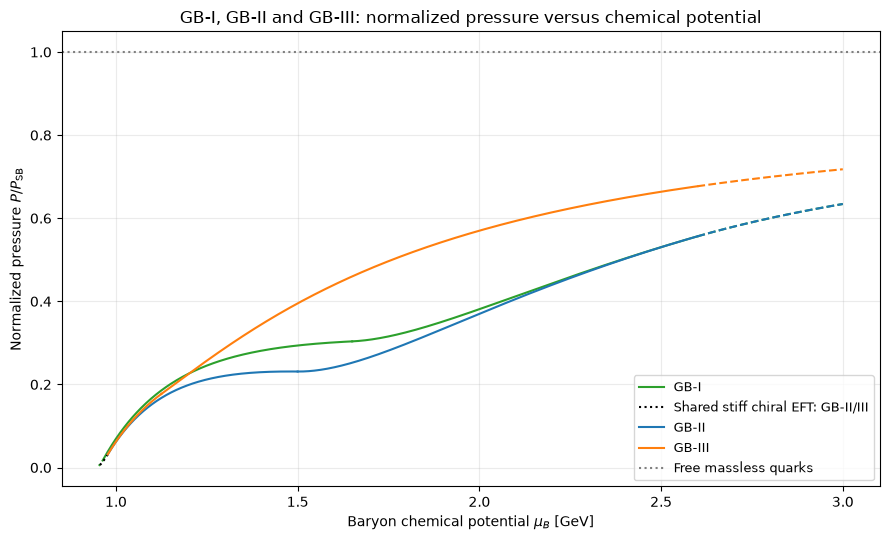

In [64]:
# Same reference pressure and units as the existing normalized comparison.
# Stefan-Boltzmann pressure
def pressure_SB(mu_B_MeV):
    mu_B_GeV = np.asarray(mu_B_MeV)/1000.0
    P_nat = 3/(4*np.pi**2)*(mu_B_GeV/3)**4
    return P_nat*1000/hbarc_GeVfm**3


# pQCD region used for comparison
mu_high_comparison = np.linspace(mu_end, 3000.0, 250)

plt.figure(figsize=(9,5.5))


# ============================================================
# GB-I: soft chiral EFT -> Bag 1 -> Bag 2 -> pQCD
# ============================================================

plt.plot(mu_chi_grid_I/1000,P_chi_grid_I/pressure_SB(mu_chi_grid_I),color="C2",linestyle=":")
plt.plot(mu_bag1_I/1000,P_bag1_I/pressure_SB(mu_bag1_I),color="C2",label="GB-I")
plt.plot(mu_bag2_I/1000,P_bag2_I/pressure_SB(mu_bag2_I),color="C2")
plt.plot(mu_high_comparison/1000,pqcd_pressure_mu(mu_high_comparison,X=X_I)/pressure_SB(mu_high_comparison), "--",color="C2")


# ============================================================
# GB-II: stiff chiral EFT -> Bag 1 -> Bag 2 -> pQCD
# ============================================================

plt.plot(mu_chi/1000,P_chi/pressure_SB(mu_chi),color="black",linestyle=":",label="Shared stiff chiral EFT: GB-II/III")
plt.plot(mu_bag1_II/1000,P_bag1_II/pressure_SB(mu_bag1_II),color="C0",label="GB-II")
plt.plot(mu_bag2_II/1000, P_bag2_II/pressure_SB(mu_bag2_II),color="C0")

plt.plot(mu_high_comparison/1000,pqcd_pressure_mu(mu_high_comparison,X=X_pqcd)/pressure_SB(mu_high_comparison),"--",color="C0")
# ============================================================
# GB-III: stiff chiral EFT -> Bag 1 -> Bag 2 -> pQCD
# ============================================================

plt.plot(mu_bag1_III/1000,P_bag1_III/pressure_SB(mu_bag1_III),color="C1",label="GB-III")
plt.plot(mu_bag2_III/1000,P_bag2_III/pressure_SB(mu_bag2_III),color="C1")
plt.plot(mu_high_comparison/1000,pqcd_pressure_mu(mu_high_comparison,X=X_III)/pressure_SB(mu_high_comparison),"--",color="C1")
plt.axhline(1,color="gray",linestyle=":",label="Free massless quarks")

plt.xlabel(r"Baryon chemical potential $\mu_B$ [GeV]")
plt.ylabel(r"Normalized pressure $P/P_{\rm SB}$")
plt.title( "GB-I, GB-II and GB-III: normalized pressure versus chemical potential")

plt.grid(True,alpha=0.25)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Comparison 2: mass-radius sequences for all three EOSs


Maximum mass = 3.064213804243708 M_sun
Radius = 15.280619645281309 km
Central pressure = 162.58512620522046 MeV/fm^3
GB III sampled maximum mass = 2.131248446510227 M_sun
GB III radius at sampled maximum = 13.414049064448678 km
GB III central pressure = 123.01915262620903 MeV/fm^3
GB I sampled maximum mass = 2.6125416076461403 M_sun
GB I radius at sampled maximum = 13.66285468752999 km
GB I central pressure = 214.87648629385666 MeV/fm^3


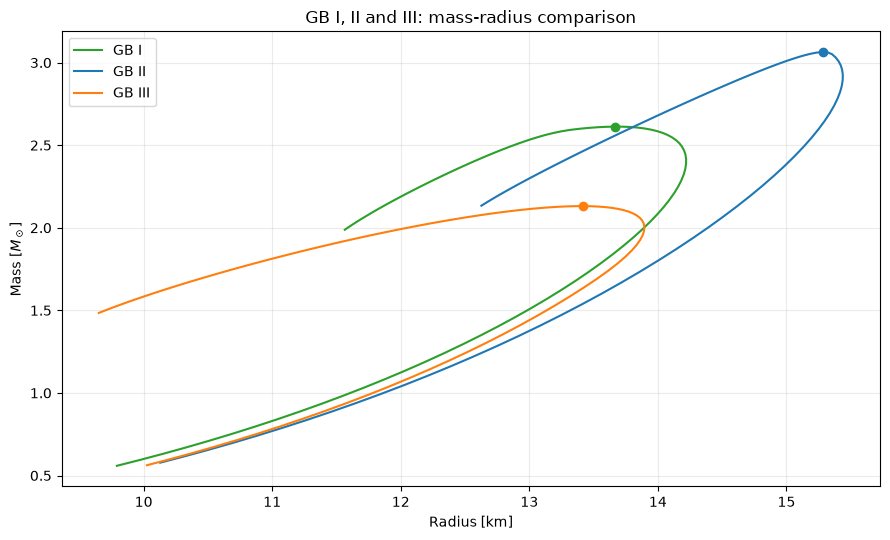

In [78]:
P_c_values = np.logspace(np.log10(10), np.log10(2500), 100)

M_values = []
R_values = []

for P_c in P_c_values:
    M,R = solve_star(P_c)
    M_values.append(M)
    R_values.append(R)

M_values = np.array(M_values)
R_values = np.array(R_values)

mask = np.isfinite(M_values) & np.isfinite(R_values)

M_good = M_values[mask]
R_good = R_values[mask]
P_good = P_c_values[mask]

imax = np.argmax(M_good)

M_max = M_good[imax]
R_max = R_good[imax]
P_c_max = P_good[imax]

print("Maximum mass =", M_max, "M_sun")
print("Radius =", R_max, "km")
print("Central pressure =", P_c_max, "MeV/fm^3")

# The EOS II sequence and variables above this line are retained unchanged.
# Use the same central pressures for the new EOS III sequence.
M_values_III = []
R_values_III = []
for central_pressure_III in P_c_values:
    mass_III, radius_III = solve_star_III(central_pressure_III)
    M_values_III.append(mass_III)
    R_values_III.append(radius_III)

M_values_III = np.array(M_values_III)
R_values_III = np.array(R_values_III)
imax_III = np.argmax(M_values_III)
P_c_max_III = P_c_values[imax_III]

print('GB III sampled maximum mass =', M_values_III[imax_III], 'M_sun')
print('GB III radius at sampled maximum =', R_values_III[imax_III], 'km')
print('GB III central pressure =', P_c_max_III, 'MeV/fm^3')

# EOS I is evaluated at the SAME central pressures as EOS II and III.
M_values_I = []
R_values_I = []
for central_pressure_I in P_c_values:
    mass_I, radius_I = solve_star_I(central_pressure_I)
    M_values_I.append(mass_I)
    R_values_I.append(radius_I)
M_values_I = np.array(M_values_I)
R_values_I = np.array(R_values_I)
imax_I = np.argmax(M_values_I)
P_c_max_I = P_c_values[imax_I]

print('GB I sampled maximum mass =', M_values_I[imax_I], 'M_sun')
print('GB I radius at sampled maximum =', R_values_I[imax_I], 'km')
print('GB I central pressure =', P_c_max_I, 'MeV/fm^3')

# Mass on the y axis; radius on the x axis.
plt.figure(figsize=(9, 5.5))
plt.plot(R_values_I, M_values_I, color='C2', label='GB I')
plt.plot(R_good, M_good, color='C0', label='GB II')
plt.plot(R_values_III, M_values_III, color='C1', label='GB III')
plt.scatter(R_values_I[imax_I], M_values_I[imax_I], color='C2', zorder=3)
plt.scatter(R_good[imax], M_good[imax], color='C0', zorder=3)
plt.scatter(R_values_III[imax_III], M_values_III[imax_III], color='C1', zorder=3)
plt.xlabel('Radius [km]')
plt.ylabel(r'Mass [$M_\odot$]')
plt.title('GB I, II and III: mass-radius comparison')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


### Comparison 3: energy density and regions inside all three stars


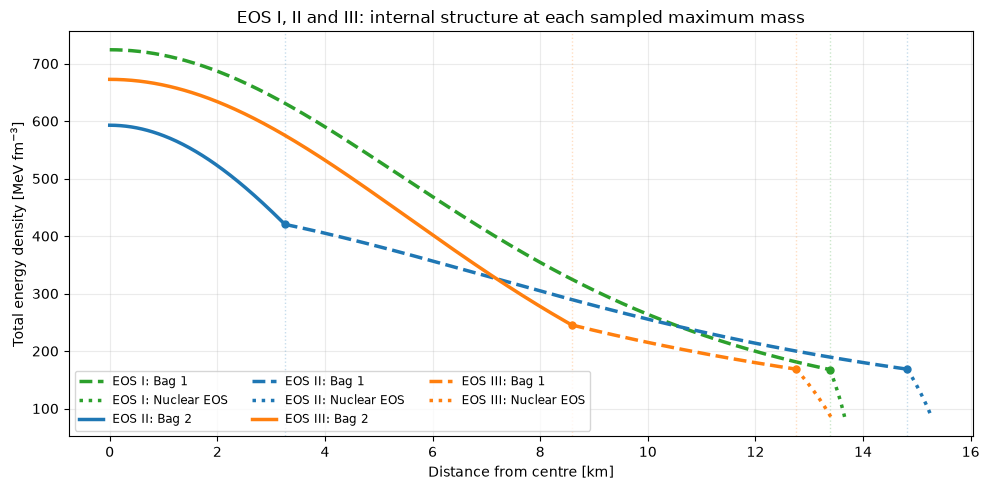

In [79]:
# EOS II must also be solved explicitly after a fresh kernel restart.
M_profile_II,R_profile_II,sol_max=solve_star(P_c_max,return_profile=True)
r_profile=sol_max.t/1000
P_profile=SI_to_MeV_fm3(sol_max.y[1])
E_profile=np.array([SI_to_MeV_fm3(full_e_density(max(p,P_surface))) for p in sol_max.y[1]])

# Calculate each model's profile at its own sampled maximum mass.
M_profile_I, R_profile_I, solution_profile_I = solve_star_I(
    P_c_max_I, return_profile=True
)
r_comparison_I = solution_profile_I.t/1000
P_comparison_I = SI_to_MeV_fm3(solution_profile_I.y[1])
E_comparison_I = np.array([
    SI_to_MeV_fm3(full_e_density_I(max(pressure, P_surface_I)))
    for pressure in solution_profile_I.y[1]
])

# Preserve the EOS III profile variables used by the existing validation cell.
M_profile_III, R_profile_III, solution_profile_III = solve_star_III(
    P_c_max_III, return_profile=True
)
r_comparison_III = solution_profile_III.t/1000
P_comparison_III = SI_to_MeV_fm3(solution_profile_III.y[1])
E_comparison_III = np.array([
    SI_to_MeV_fm3(full_e_density_III(max(pressure, P_surface)))
    for pressure in solution_profile_III.y[1]
])

# Each model supplies its OWN nuclear and bag joining pressures.
profiles = [
    ('EOS I', r_comparison_I, P_comparison_I, E_comparison_I,
     P_bag_split_I, P_begin_I, P_qcd_start_I, 'C2'),
    ('EOS II', r_profile, P_profile, E_profile,
     P_bag_split_II, P_begin, P_qcd_start, 'C0'),
    ('EOS III', r_comparison_III, P_comparison_III, E_comparison_III,
     P_bag_split_III, P_begin, P_qcd_start_III, 'C1')
]

plt.figure(figsize=(10, 5))
for name, radius, pressure, energy, bag_join, nuclear_join, qcd_join, colour in profiles:
    radius = np.r_[0, radius]
    pressure = np.r_[pressure[0], pressure]
    energy = np.r_[energy[0], energy]

    # Include only boundaries that this particular star actually reaches.
    internal_pressures = [boundary for boundary in [qcd_join, bag_join, nuclear_join]
                          if pressure[-1] < boundary < pressure[0]]
    pressure_edges = [pressure[0]] + internal_pressures + [pressure[-1]]
    radius_edges = np.interp(pressure_edges, pressure[::-1], radius[::-1])

    for j in range(len(radius_edges) - 1):
        inner_radius, outer_radius = radius_edges[j:j+2]
        middle_pressure = (pressure_edges[j] + pressure_edges[j+1])/2
        if middle_pressure >= qcd_join:
            region_name, line_style = 'pQCD', '-.'
        elif middle_pressure >= bag_join:
            region_name, line_style = 'Bag 2', '-'
        elif middle_pressure >= nuclear_join:
            region_name, line_style = 'Bag 1', '--'
        else:
            region_name, line_style = 'Nuclear EOS', ':'

        inside = (radius > inner_radius) & (radius < outer_radius)
        region_radius = np.r_[inner_radius, radius[inside], outer_radius]
        region_energy = np.interp(region_radius, radius, energy)
        plt.plot(region_radius, region_energy, color=colour,
                 linestyle=line_style, linewidth=2.5,
                 label=f'{name}: {region_name}')

    for boundary_radius in radius_edges[1:-1]:
        plt.axvline(boundary_radius, color=colour, linestyle=':', alpha=0.25, linewidth=1)
        plt.scatter(boundary_radius, np.interp(boundary_radius, radius, energy),
                    color=colour, s=25, zorder=3)

plt.xlabel('Distance from centre [km]')
plt.ylabel(r'Total energy density [MeV fm$^{-3}$]')
plt.title('EOS I, II and III: internal structure at each sampled maximum mass')
plt.grid(True, alpha=0.25)
plt.legend(fontsize=8.5, ncol=3)
plt.tight_layout()
plt.show()


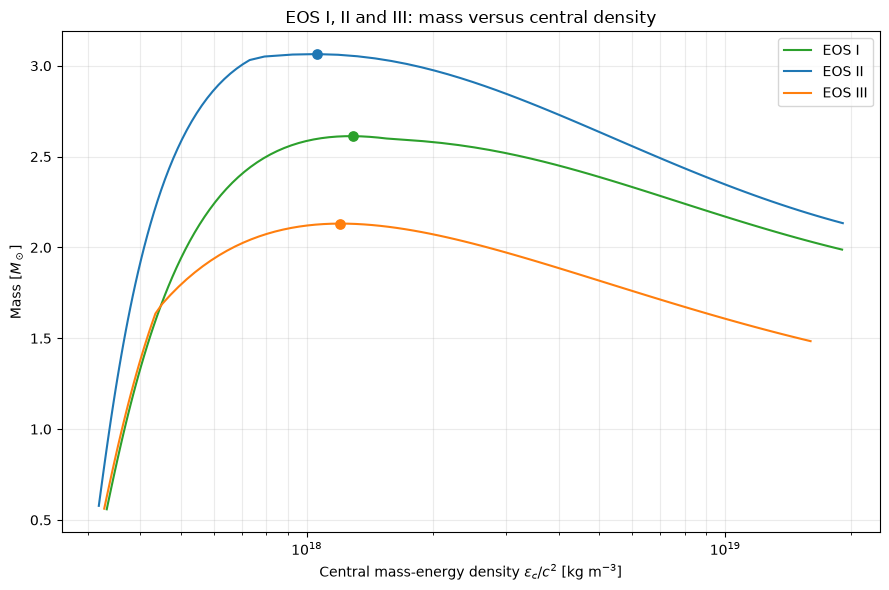

In [80]:
# Central mass-energy density [kg/m^3]
# Each entry contains:
# EOS name, central pressures, masses, energy-density function, colour.
sequences = [
    ("EOS I", P_c_values, M_values_I, full_e_density_I, "C2"),
    ("EOS II", P_good, M_good, full_e_density, "C0"),
    ("EOS III", P_c_values, M_values_III, full_e_density_III, "C1")
]

plt.figure(figsize=(9, 6))

for name, central_pressures, masses, energy_function, colour in sequences:

    # Convert central pressure [MeV/fm^3] to SI pressure,
    # calculate total energy density, then divide by c^2.
    central_densities = np.array([
        energy_function(MeV_fm3_to_SI(pressure)) / c**2
        for pressure in central_pressures
    ])

    plt.plot(
        central_densities,
        masses,
        color=colour,
        label=name
    )

    # Mark this EOS's largest sampled mass.
    peak_index = np.argmax(masses)

    plt.scatter(
        central_densities[peak_index],
        masses[peak_index],
        color=colour,
        s=45,
        zorder=3
    )

plt.xscale("log")
plt.xlabel(r"Central mass-energy density $\varepsilon_c/c^2$ [kg m$^{-3}$]")
plt.ylabel(r"Mass [$M_\odot$]")
plt.title("EOS I, II and III: mass versus central density")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

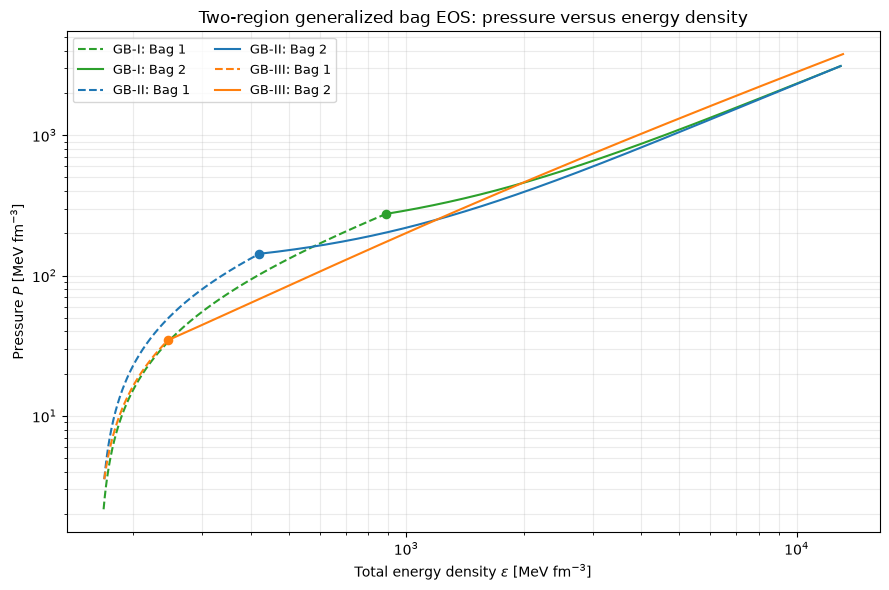

In [81]:
import numpy as np
import matplotlib.pyplot as plt

# Name, coefficients, starting mu, joining mu, ending mu, colour
bag_models = [
    ("GB-I", bag_coeff_I, mu_begin_I, mu_split_I, mu_end_I, "C2"),
    ("GB-II", bag_coeff_II, mu_begin, mu_split_II, mu_end, "C0"),
    ("GB-III", bag_coeff_III, mu_begin, mu_split_III, mu_end_III, "C1")
]

plt.figure(figsize=(9, 6))

for name, coeffs, mu_start, mu_split, mu_stop, colour in bag_models:

    # Evaluate each region separately.
    mu1 = np.linspace(mu_start, mu_split, 500)
    mu2 = np.linspace(mu_split, mu_stop, 500)

    P1, n1, E1, cs1 = bag_thermo(mu1, coeffs, 1)
    P2, n2, E2, cs2 = bag_thermo(mu2, coeffs, 2)

    plt.plot(
        E1, P1, "--", color=colour,
        label=f"{name}: Bag 1"
    )

    plt.plot(
        E2, P2, "-", color=colour,
        label=f"{name}: Bag 2"
    )

    # Pressure and energy agree on both sides of this point.
    plt.scatter(
        E1[-1], P1[-1],
        color=colour, s=35, zorder=3
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Total energy density $\varepsilon$ [MeV fm$^{-3}$]")
plt.ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
plt.title("Two-region generalized bag EOS: pressure versus energy density")
plt.grid(True, which="both", alpha=0.25)
plt.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

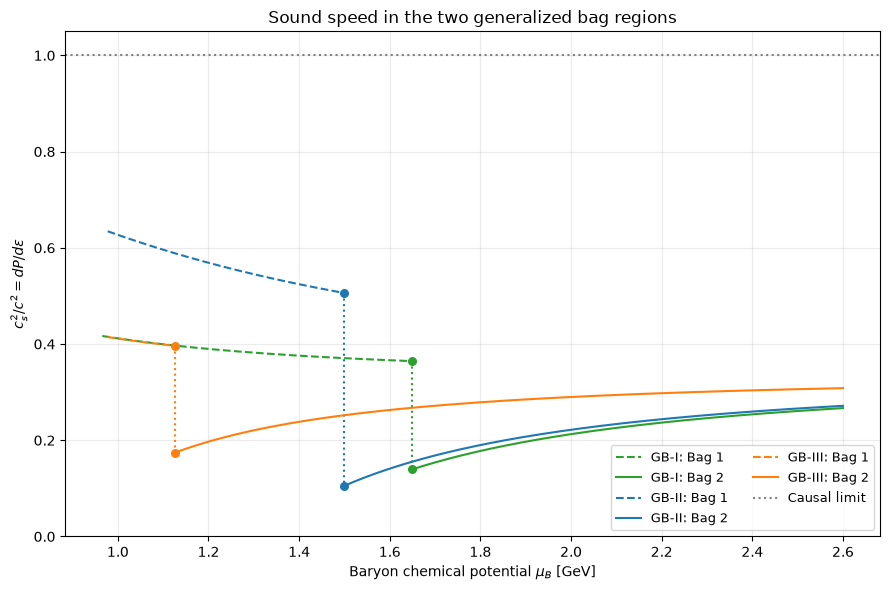

In [82]:
plt.figure(figsize=(9, 6))

for name, coeffs, mu_start, mu_split, mu_stop, colour in bag_models:

    mu1 = np.linspace(mu_start, mu_split, 500)
    mu2 = np.linspace(mu_split, mu_stop, 500)

    P1, n1, E1, cs1 = bag_thermo(mu1, coeffs, 1)
    P2, n2, E2, cs2 = bag_thermo(mu2, coeffs, 2)

    # Convert chemical potential from MeV to GeV for plotting.
    plt.plot(
        mu1 / 1000, cs1, "--", color=colour,
        label=f"{name}: Bag 1"
    )

    plt.plot(
        mu2 / 1000, cs2, "-", color=colour,
        label=f"{name}: Bag 2"
    )

    # Show the discontinuous sound-speed change at the join.
    plt.plot(
        [mu_split / 1000, mu_split / 1000],
        [cs1[-1], cs2[0]],
        ":", color=colour
    )

    plt.scatter(
        [mu_split / 1000, mu_split / 1000],
        [cs1[-1], cs2[0]],
        color=colour, s=30, zorder=3
    )

plt.axhline(
    1.0, color="gray", linestyle=":",
    label="Causal limit"
)

plt.xlabel(r"Baryon chemical potential $\mu_B$ [GeV]")
plt.ylabel(r"$c_s^2/c^2 = dP/d\varepsilon$")
plt.title("Sound speed in the two generalized bag regions")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

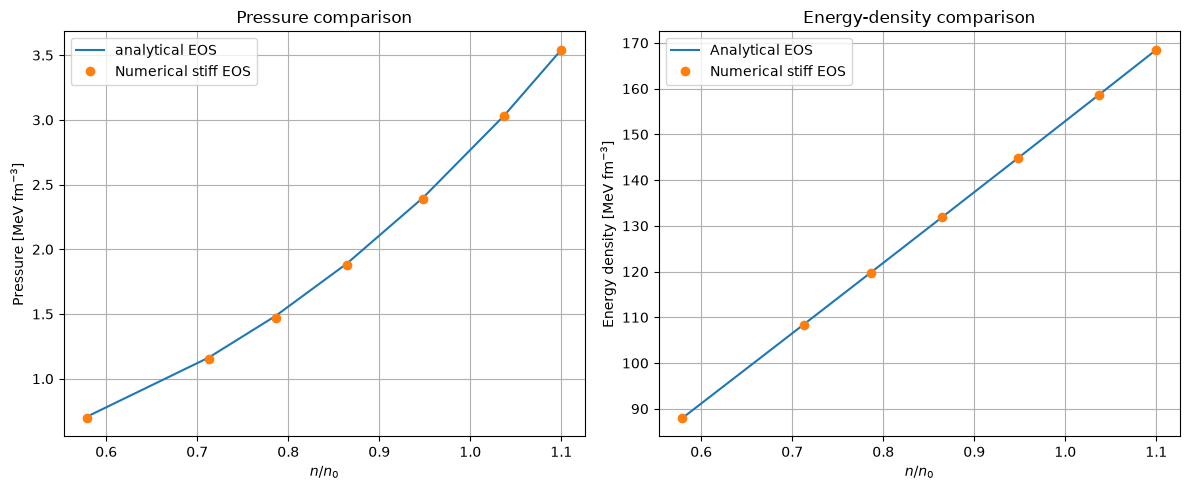

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pressure comparison
axes[0].plot(
    density_ratio, pressure_analytical,
    label="analytical EOS"
)
axes[0].plot(
    density_ratio, pressure_numerical,
    "o", label="Numerical stiff EOS"
)

axes[0].set_xlabel(r"$n/n_0$")
axes[0].set_ylabel(r"Pressure [MeV fm$^{-3}$]")
axes[0].set_title("Pressure comparison")
axes[0].legend()
axes[0].grid()

# Total energy-density comparison
axes[1].plot(
    density_ratio, energy_analytical,
    label="Analytical EOS"
)
axes[1].plot(
    density_ratio, energy_numerical,
    "o", label="Numerical stiff EOS"
)

axes[1].set_xlabel(r"$n/n_0$")
axes[1].set_ylabel(r"Energy density [MeV fm$^{-3}$]")
axes[1].set_title("Energy-density comparison")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()